In [1]:
import pandas as pd
import numpy as np
from statistics import mean
import os
import sys

# Ruta absoluta al directorio src
src_path = os.path.abspath("../src")
sys.path.append(src_path)

# Ahora puedes importar el módulo utils
from utils.exploration_utils import preprocess_data, evaluar_escenarios_trading, calcular_features_vela
from utils.exploration_utils import feature_engineering_rsi, sma_engineering_from_close, analizar_metricas_por_umbral


pd.set_option('display.max_columns', None)


In [2]:
def read_csv_files(folder_path):
    # List all CSV files in the folder
    all_files = os.listdir(folder_path)
    csv_files = [os.path.join(folder_path, file) for file in all_files if file.endswith('.csv')]
    
    # Read and concatenate all CSV files into a single DataFrame
    combined_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
    
    return combined_df

In [3]:
# Read Data:
folder_path = '../data/EURUSD/5mins'
df_EURUSD_5min = read_csv_files(folder_path)
df_EURUSD_5min = preprocess_data(df_EURUSD_5min)

In [4]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

X = 24
# Create sliding window view of future close values
future_high_values = sliding_window_view(df_EURUSD_5min['high'].values, window_shape=X)
future_low_values = sliding_window_view(df_EURUSD_5min['low'].values, window_shape=X)
future_close_values = sliding_window_view(df_EURUSD_5min['close'].values, window_shape=X)

# Pad with NaN at the end since we can't look into the future for the last X-1 rows

padding = np.full((X-1, X), np.nan)
future_high_values = np.vstack([future_high_values, padding])
future_low_values = np.vstack([future_low_values, padding])
future_close_values = np.vstack([future_close_values, padding])

# Assign to DataFrame
df_EURUSD_5min['future_high_values'] = future_high_values.tolist()
df_EURUSD_5min['future_low_values'] = future_low_values.tolist()
df_EURUSD_5min['future_close_values'] = future_close_values.tolist()

# Mostrar las primeras filas para verificar
df_EURUSD_5min.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,future_high_values,future_low_values,future_close_values
0,20100103 17:15:00 US/Eastern,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"[1.4309, 1.43175, 1.4318, 1.4318, 1.43285, 1.4...","[1.4308, 1.4309, 1.4315, 1.43095, 1.4311, 1.43...","[1.4309, 1.4317, 1.4317, 1.4311, 1.43245, 1.43..."
1,20100103 17:20:00 US/Eastern,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4..."
2,20100103 17:25:00 US/Eastern,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4..."
3,20100103 17:30:00 US/Eastern,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4..."
4,20100103 17:35:00 US/Eastern,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1...."


In [5]:
df_EURUSD_5min[['compra_resultado', 'compra_velas', 'compra_pips',
        'venta_resultado', 'venta_velas', 'venta_pips']] = df_EURUSD_5min.apply(
    lambda row: evaluar_escenarios_trading(row, pips_objetivo=20, pips_stop=5),
    axis=1
)

In [6]:
df_EURUSD_5min.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,future_high_values,future_low_values,future_close_values,compra_resultado,compra_velas,compra_pips,venta_resultado,venta_velas,venta_pips
0,20100103 17:15:00 US/Eastern,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"[1.4309, 1.43175, 1.4318, 1.4318, 1.43285, 1.4...","[1.4308, 1.4309, 1.4315, 1.43095, 1.4311, 1.43...","[1.4309, 1.4317, 1.4317, 1.4311, 1.43245, 1.43...",OBJETIVO_ALCANZADO,8,27.5,STOP_ALCANZADO,2,-8.5
1,20100103 17:20:00 US/Eastern,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4...",STOP_ALCANZADO,1,-8.0,STOP_ALCANZADO,4,-11.5
2,20100103 17:25:00 US/Eastern,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4...",STOP_ALCANZADO,2,-7.5,STOP_ALCANZADO,3,-11.5
3,20100103 17:30:00 US/Eastern,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4...",OBJETIVO_ALCANZADO,5,25.5,STOP_ALCANZADO,1,-7.0
4,20100103 17:35:00 US/Eastern,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1....",STOP_ALCANZADO,1,-13.5,STOP_ALCANZADO,4,-12.0


In [7]:
df_EURUSD_5min.iloc[1]

date                                        20100103 17:20:00 US/Eastern
open                                                              1.4309
high                                                             1.43175
low                                                               1.4309
close                                                             1.4317
volume                                                                -1
barCount                                                              -1
datetime                                       2010-01-03 17:20:00-05:00
Year                                                                2010
Month                                                             201001
Day                                                                    3
Date                                                            20100103
Hour                                                                  17
Minute                                             

In [8]:
print(df_EURUSD_5min.iloc[1]['close'])
print("-------ESCENARIO COMPRA-------")

print(df_EURUSD_5min.iloc[1]['close']+20/10000)
print(df_EURUSD_5min.iloc[1]['close']-5/10000)

print("-------ESCENARIO VENTA-------")
print(df_EURUSD_5min.iloc[1]['close']-20/10000)
print(df_EURUSD_5min.iloc[1]['close']+5/10000)

print("-------VALORES FUTUROS-------")
print(df_EURUSD_5min.iloc[1]['future_high_values'])
print(df_EURUSD_5min.iloc[1]['future_low_values'])

1.4317
-------ESCENARIO COMPRA-------
1.4337
1.4312
-------ESCENARIO VENTA-------
1.4297
1.4322
-------VALORES FUTUROS-------
[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1.43375, 1.43265, 1.433, 1.43345, 1.4333, 1.43315, 1.43315, 1.43245, 1.43285, 1.4334, 1.4329, 1.4329, 1.432, 1.43165, 1.43115, 1.43085, 1.4303]
[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1.43225, 1.43235, 1.43285, 1.43245, 1.43285, 1.4323, 1.43215, 1.4324, 1.43285, 1.43265, 1.43185, 1.43165, 1.4304, 1.42965, 1.429, 1.42895]


In [9]:
# Calculate counts
counts = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts()

# Calculate percentages
percentages = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts(normalize=True) * 100

# Combine counts and percentages
results = pd.DataFrame({
    'Count': counts,
    'Percentage': percentages.round(2)
})

print(results)

                                        Count  Percentage
compra_resultado   venta_resultado                       
STOP_ALCANZADO     STOP_ALCANZADO      423837       41.13
SIN_ALCANCE        STOP_ALCANZADO      187932       18.24
STOP_ALCANZADO     SIN_ALCANCE         184736       17.93
OBJETIVO_ALCANZADO STOP_ALCANZADO       83618        8.11
STOP_ALCANZADO     OBJETIVO_ALCANZADO   83436        8.10
SIN_ALCANCE        SIN_ALCANCE          66905        6.49


In [10]:
# Create two filtered dataframes
compra_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['compra_resultado'] == 'SIN_ALCANCE']
venta_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['venta_resultado'] == 'SIN_ALCANCE']

print(compra_sin_alcance.compra_pips.mean())
print(venta_sin_alcance.venta_pips.mean())


4.2443978745280875
4.162482413817771


In [11]:
df_EURUSD_5min = sma_engineering_from_close(df_EURUSD_5min, [10,40,100])

In [12]:
df_EURUSD_5min.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'barCount',
       'datetime', 'Year', 'Month', 'Day', 'Date', 'Hour', 'Minute',
       'future_high_values', 'future_low_values', 'future_close_values',
       'compra_resultado', 'compra_velas', 'compra_pips', 'venta_resultado',
       'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100',
       'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10',
       'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40',
       'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100',
       'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100',
       'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100',
       'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40',
       'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10',
       'acc_SMA_40', 'acc_SMA_100', 'SMA_10_mo

In [13]:
df_EURUSD_5min["multiclass_target"] = np.where(
    (df_EURUSD_5min['compra_resultado'] == 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] != 'OBJETIVO_ALCANZADO'),
    'objetivo_compra_alcanzado',
    np.where(
        (df_EURUSD_5min['compra_resultado'] != 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] == 'OBJETIVO_ALCANZADO'),
        'objetivo_venta_alcanzado',
        'no_objetivo_alcanzado'
    )
)

In [14]:
df_EURUSD_5min.multiclass_target.value_counts()/df_EURUSD_5min.shape[0]

multiclass_target
no_objetivo_alcanzado        0.837891
objetivo_compra_alcanzado    0.081143
objetivo_venta_alcanzado     0.080966
Name: count, dtype: float64

In [15]:
# Filtrar datos de entrenamiento y prueba por fecha
df_train = df_EURUSD_5min[df_EURUSD_5min['Date'] < "20230101"]
df_test = df_EURUSD_5min[df_EURUSD_5min['Date'] >= "20230101"]

In [16]:
# Definir las características (X) y el target (y)
features = ['diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10',
       'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40',
       'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100',
       'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100',
       'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100',
       'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40',
       'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10',
       'acc_SMA_40', 'acc_SMA_100', 'SMA_10_momentum', 'SMA_10_pct_momentum',
       'SMA_40_momentum', 'SMA_40_pct_momentum', 'SMA_100_momentum',
       'SMA_100_pct_momentum', 'SMA_10_slope_mean', 'SMA_40_slope_mean',
       'SMA_100_slope_mean']


X_train = df_train[features]
y_train = df_train['multiclass_target']

X_test = df_test[features]
y_test = df_test['multiclass_target']

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [18]:
# Create and train the RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_features='sqrt'
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Print classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.92      0.57      0.70     81581
objetivo_compra_alcanzado       0.10      0.40      0.16      5197
 objetivo_venta_alcanzado       0.10      0.39      0.16      5341

                 accuracy                           0.55     92119
                macro avg       0.37      0.45      0.34     92119
             weighted avg       0.83      0.55      0.64     92119



In [19]:
y_pred_proba = rf_model.predict_proba(X_test)

In [20]:
from utils.exploration_utils import analizar_metricas_por_umbral

Buy Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,5.70%,"91,125","-35,041"
1,0.15,5.74%,"90,271","-31,210"
2,0.20,5.79%,"89,171","-26,985"
3,0.25,6.13%,"81,769","-22,541"
4,0.30,7.76%,"49,914","-17,900"
5,0.35,9.85%,"21,834","-7,927"
6,0.40,12.16%,"9,041","-2,637"
7,0.45,13.97%,"4,488",-834
8,0.50,15.32%,"2,553",-380
9,0.55,16.70%,"1,461",199



Sell Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,5.85%,"91,146","-47,279"
1,0.15,5.89%,"90,346","-43,709"
2,0.20,5.94%,"89,250","-39,365"
3,0.25,6.29%,"81,335","-35,856"
4,0.30,8.04%,"46,083","-24,179"
5,0.35,9.92%,"21,410","-10,901"
6,0.40,12.03%,"9,250","-3,989"
7,0.45,14.00%,"4,728",-907
8,0.50,15.69%,"2,721",112
9,0.55,17.77%,"1,570",637


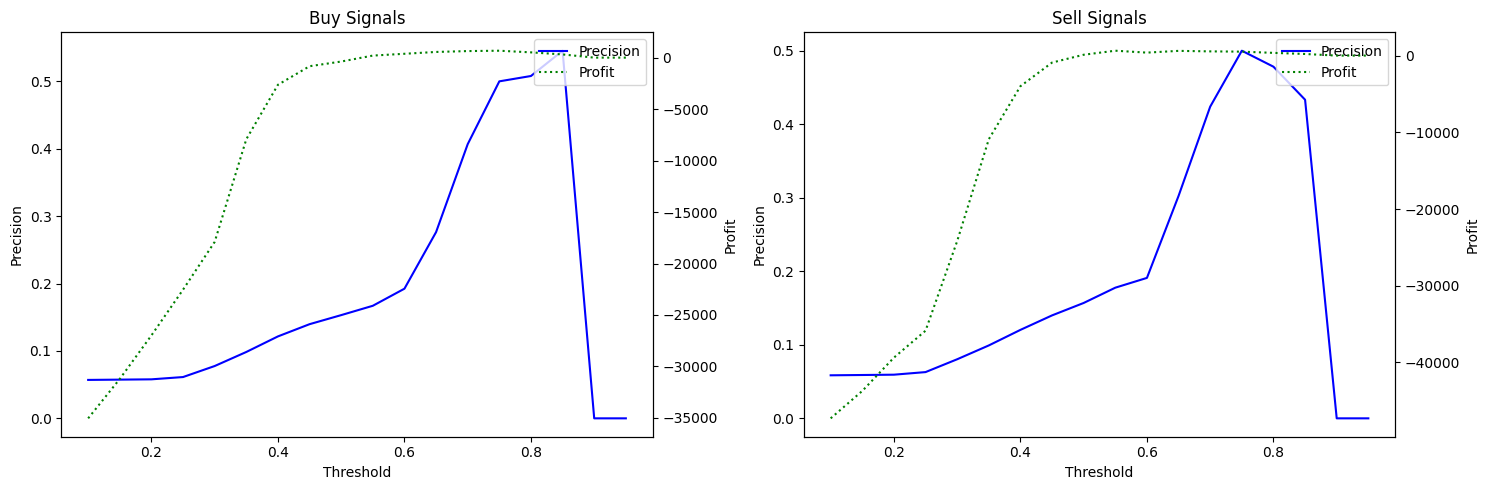


Mejor umbral para compras:
Threshold: 0.75
Profit: 672
Precision: 50.00%

Mejor umbral para ventas:
Threshold: 0.55
Profit: 637
Precision: 17.77%


In [21]:
# Ejemplo de uso
compra_df, venta_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=20,
    pip_stop=5
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")

In [ ]:
import lightgbm as lgb


In [29]:
from sklearn.preprocessing import LabelEncoder
# 1. Preparar los datos
# Codificar la variable objetivo
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


In [30]:
# Definir parámetros para multiclass classification
params = {
    'objective': 'multiclass',
    'num_class': len(le.classes_),
    'metric': 'multi_logloss',
    'verbosity': -1,
    'seed': 42
}

# Create new datasets with encoded labels
lgb_train = lgb.Dataset(X_train, y_train_encoded)
lgb_test = lgb.Dataset(X_test, y_test_encoded, reference=lgb_train)

# Entrenar el modelo
model = lgb.train(
    params,
    lgb_train,
    valid_sets=[lgb_test]
)

In [31]:
# Predecir
y_pred_proba = model.predict(X_test)  

Buy Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,10.67%,"19,024","-9,682"
1,0.15,16.17%,"1,787",-27
2,0.20,28.74%,247,657
3,0.25,43.65%,126,781
4,0.30,46.60%,103,721
5,0.35,47.83%,92,676
6,0.40,49.35%,77,601
7,0.45,56.25%,64,607
8,0.50,65.12%,43,494
9,0.55,72.73%,22,299



Sell Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,10.81%,"18,605","-12,024"
1,0.15,15.51%,"2,225",-322
2,0.20,32.08%,212,721
3,0.25,45.37%,108,730
4,0.30,50.67%,75,611
5,0.35,49.18%,61,481
6,0.40,41.18%,51,306
7,0.45,42.11%,38,246
8,0.50,59.09%,22,224
9,0.55,54.55%,11,95


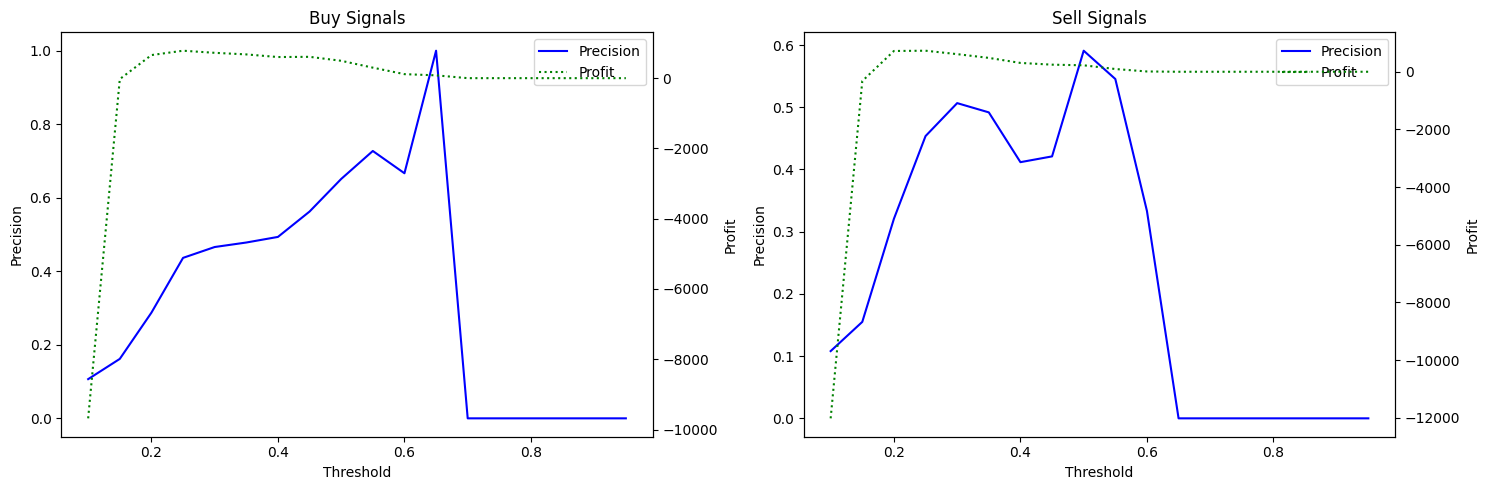


Mejor umbral para compras:
Threshold: 0.25
Profit: 781
Precision: 43.65%

Mejor umbral para ventas:
Threshold: 0.25
Profit: 730
Precision: 45.37%


In [33]:
# Ejemplo de uso
compra_df, venta_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=20,
    pip_stop=5
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")